# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [6]:
# Instalacion de dependencias
!pip install nltk pandas numpy matplotlib psutil requests


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import re, time, statistics, unicodedata, os, sys
from collections import Counter, defaultdict

import nltk
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

nltk.download("gutenberg", quiet=True)
from nltk.corpus import gutenberg

In [8]:
# Cargar el corpus
ids_docs = sorted(gutenberg.fileids())
docs_raw = {fid: gutenberg.raw(fid) for fid in ids_docs}

# Numero de documentos
print(f"Número de documentos: {len(docs_raw)}\n")
tabla = pd.DataFrame({
    "doc_id": ids_docs,
    "caracteres": [len(docs_raw[f]) for f in ids_docs],
    "bytes": [len(docs_raw[f].encode("utf-8")) for f in ids_docs],
    "palabras": [len(docs_raw[f].split()) for f in ids_docs],
})
display(tabla)

# Tokenizacion y normalizacion
TOKEN_RE = re.compile(r"[a-z0-9]+")

def normalizar(texto):
    texto = texto.lower() # Minusculas
    texto = unicodedata.normalize("NFKD", texto) # quitar tildes
    return "".join(c for c in texto if not unicodedata.combining(c)) 

def tokenizar(texto):
    return TOKEN_RE.findall(normalizar(texto))

# Tokenizar todo el vocabulario
docs_tok = {fid: tokenizar(txt) for fid, txt in docs_raw.items()}
print("\nTokens totales:", sum(len(t) for t in docs_tok.values()))
print("Vocabulario:", len({t for tokens in docs_tok.values() for t in tokens}))

Número de documentos: 18



,doc_id,caracteres,bytes,palabras
0,austen-emma.txt,887071,887071,158167
1,austen-persuasion.txt,466292,466292,83308
2,austen-sense.txt,673022,673022,118675
3,bible-kjv.txt,4332554,4332554,821133
4,blake-poems.txt,38153,38153,6845
5,bryant-stories.txt,249439,249439,45988
6,burgess-busterbrown.txt,84663,84663,15870
7,carroll-alice.txt,144395,144395,26443
8,chesterton-ball.txt,457450,457455,81598
9,chesterton-brown.txt,406629,406629,71626



Tokens totales: 2199209
Vocabulario: 41838


**El corpus de NLTK tiene 18 documentos, y al tokenizar sus terminos nos dio un aproximado de 2 millones de tokens, que al momento de filtrar y conseguir el vocabulario se redució a 41838 terminos unicos.**

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [9]:
# Busqueda secuencial
def busqueda_secuencial(termino, docs):
    termino = normalizar(termino)          # Normalizar 
    resultado = []
    for doc_id, tokens in docs.items():    # loop de documentos
        for tok in tokens:                 # loop de tokes de los documentos
            if tok == termino:
                resultado.append(doc_id)
                break                      # se sale del loop si ya se encuentra
    return resultado

In [46]:
# seleccion de palabras frecuentes, infrecuentes e inexistentes
frecuente   = ["the", "sea", "love"]
poco_frec   = ["whale", "monster", "corpse"]
inexistente = ["boludo", "shakespear", "gutemberg"]

# Ejemplos de consultas
consultas = {
    "frecuente": frecuente,
    "poco frecuente": poco_frec,
    "inexistente": inexistente,
}

pares = [(cat, t) for cat, terminos in consultas.items() for t in terminos]

for cat, termino in pares:
    res = busqueda_secuencial(termino, docs_tok)
    print(f"{cat:15s} '{termino}': {res[:3]}{'...' if len(res)>3 else ''}")

frecuente       'the': ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt']...
frecuente       'sea': ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt']...
frecuente       'love': ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt']...
poco frecuente  'whale': ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt']...
poco frecuente  'monster': ['bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt']...
poco frecuente  'corpse': ['austen-persuasion.txt', 'bible-kjv.txt', 'chesterton-ball.txt']...
inexistente     'boludo': []
inexistente     'shakespear': []
inexistente     'gutemberg': []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [49]:
REPETICIONES = 30 

def medir_tiempo(func, *args, repeticiones=REPETICIONES):
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter_ns()
        func(*args)
        t1 = time.perf_counter_ns()
        tiempos.append((t1 - t0) / 1e6) # formato en milisegundos
    return statistics.mean(tiempos)

filas = []
for categoria, termino in pares:
    t = medir_tiempo(busqueda_secuencial, termino, docs_tok)
    filas.append({"tipo": categoria, "termino": termino, "t_secuencial_ms": t})
display(pd.DataFrame(filas))

,tipo,termino,t_secuencial_ms
0,frecuente,the,0.00921
1,frecuente,sea,4.09530
2,frecuente,love,2.11742
3,poco frecuente,whale,17.80198
4,poco frecuente,monster,23.55387
5,poco frecuente,corpse,70.10098
6,inexistente,boludo,112.34027
7,inexistente,shakespear,92.38604
8,inexistente,gutemberg,94.43047


**Los terminos inexistentes tienen el mayor tiempo de búsqueda porque se debe recorrer todo el corpus para verificar que no existe, mientras menos frecuencia documental tengan entonces más prolongada se vuelve su busqueda**

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [36]:
# Indice invertido
def construir_indice(docs):
    indice = defaultdict(set)
    for doc_id, tokens in docs.items():
        for token in tokens:
            indice[token].add(doc_id)
    return {termino: sorted(ids) for termino, ids in indice.items()}

In [37]:
t0 = time.perf_counter_ns()
indice = construir_indice(docs_tok)
print(f"Índice construido en {(time.perf_counter_ns()-t0)/1e6:.1f} ms")
universo = sorted(docs_tok.keys())
print("Tamaño del vocabulario:", len(indice))


Índice construido en 404.9 ms
Tamaño del vocabulario: 41838


In [50]:
# Listas de postings y DFs
for cat, t in pares:
    p = indice.get(t, [])
    print(f"{cat:15s} '{t}': DF={len(p)} -> {p}")

frecuente       'the': DF=18 -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
frecuente       'sea': DF=16 -> ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
frecuente       'love': DF=15 -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-s

**Con la revisión de los Postings se puede ver el comportamiento anterior, mientras menos frecuencia tenga un termino, su busqueda se puede prolongar más.**

In [39]:
# Consultas booleanas
def and_postings(a, b):
    i = j = 0; res = []
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            res.append(a[i]); i += 1; j += 1
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return res

def or_postings(a, b):
    i = j = 0; res = []
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            res.append(a[i]); i += 1; j += 1
        elif a[i] < b[j]:
            res.append(a[i]); i += 1
        else:
            res.append(b[j]); j += 1
    res.extend(a[i:]); res.extend(b[j:])
    return res

def diff_postings(a, b):
    i = j = 0; res = []
    while i < len(a):
        if j >= len(b) or a[i] < b[j]:
            res.append(a[i]); i += 1
        elif a[i] == b[j]:
            i += 1; j += 1
        else:
            j += 1
    return res

def postings(indice, termino):
    return indice.get(normalizar(termino), [])

In [40]:
def consulta_indice(q, indice, universo):
    op, *terms = q
    p = [postings(indice, t) for t in terms]
    if op == "TERM":    return p[0]
    if op == "AND":     return and_postings(p[0], p[1])
    if op == "OR":      return or_postings(p[0], p[1])
    if op == "NOT":     return diff_postings(universo, p[0])
    if op == "AND_NOT": return diff_postings(p[0], p[1])
    raise ValueError(op)

# Mismas consultas pero con busqueda secuencial
def consulta_secuencial(q, docs):
    op, *terms = q
    s = [set(busqueda_secuencial(t, docs)) for t in terms]
    todos = set(docs)
    if op == "TERM":    r = s[0]
    elif op == "AND":   r = s[0] & s[1]
    elif op == "OR":    r = s[0] | s[1]
    elif op == "NOT":   r = todos - s[0]
    elif op == "AND_NOT": r = s[0] - s[1]
    else: raise ValueError(op)
    return sorted(r)

print("\n--- Consultas booleanas con índice ---")
for q in [("TERM", "whale"),
          ("AND", "whale", "sea"),
          ("OR", "whale", "emma"),
          ("NOT", "whale"),
          ("AND_NOT", "the", "whale")]:
    print(q, "->", consulta_indice(q, indice, universo))



--- Consultas booleanas con índice ---
('TERM', 'whale') -> ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
('AND', 'whale', 'sea') -> ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
('OR', 'whale', 'emma') -> ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
('NOT', 'whale') -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'blake-poems.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-macbeth.txt']
('AND_NOT', 'the', 'whale') -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'blake-poems.txt', 'burgess-bu

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [52]:
consultas = [("TERM", t) for _, t in pares] + [
    ("AND", "whale", "sea"),
    ("OR", "whale", "emma"),
    ("NOT", "whale"),
    ("AND_NOT", "the", "whale"),
]

filas = []
for q in consultas:
    r_sec = consulta_secuencial(q, docs_tok)
    r_idx = consulta_indice(q, indice, universo)
    assert r_sec == r_idx, f"¡Resultados distintos en {q}!"   # verificación de igualdad

    t_sec = medir_tiempo(consulta_secuencial, q, docs_tok)
    t_idx = medir_tiempo(consulta_indice, q, indice, universo)
    filas.append({
        "consulta": " ".join(q),
        "docs": len(r_idx),
        "iguales": r_sec == r_idx,
        "Tiempo B.Secuencial": t_sec,
        "Tiempo B.Indice": t_idx,
        "Proporcion de velocidad": t_sec / t_idx if t_idx > 0 else float("inf"),
    })

pd.set_option("display.float_format", lambda x: f"{x:.5f}")
display(pd.DataFrame(filas))

,consulta,docs,iguales,Tiempo B.Secuencial,Tiempo B.Indice,Proporcion de velocidad
0,TERM the,18,True,0.00740,0.00099,7.50338
1,TERM sea,16,True,4.37019,0.00110,3984.97264
2,TERM love,15,True,1.91188,0.00108,1775.73994
3,TERM whale,6,True,17.63674,0.00131,13463.15776
4,TERM monster,6,True,22.82246,0.00146,15667.59268
5,TERM corpse,7,True,23.00641,0.00168,13721.51491
6,TERM boludo,0,True,28.41235,0.00179,15872.82123
7,TERM shakespear,0,True,27.15422,0.00164,16557.45325
8,TERM gutemberg,0,True,27.03410,0.00157,17219.17197
9,AND whale sea,6,True,20.89180,0.00373,5601.01787


**Ambos métodos logran llegar a los mismos resultados, pero es más evidente que la búsqueda por índice inverso es más eficiente y con una complejidad algoritmica más simple. La columna de proporcion nos podemos dar cuenta que es mucho mas eficiente al momento de buscar terminos inexistentes que la busqueda secuencial que recorre todo el corpus para poder determinar su presencia.**

### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [54]:
# Dependencias
import requests, zipfile, tarfile, json, random

In [58]:
# Tratamiento del corpus grande
ZIP_PATH = "txt-files.tar.zip"
CACHE_JSON = "libros_validos.json"
DIR_CORPUS = "corpus_grande"

def abrir_tar(zf):
    nombre_tar = [n for n in zf.namelist() if n.endswith(".tar")][0]
    return tarfile.open(fileobj=zf.open(nombre_tar), mode="r|")

with zipfile.ZipFile(ZIP_PATH) as zf:
    print(zf.namelist())
    with abrir_tar(zf) as tar:
        for i, m in enumerate(tar):
            print(m.name, m.size)
            if i >= 15: break
# Recoleccion de los documentos txt con versiones
def id_libro(nombre):
    base = os.path.basename(nombre).lower()
    m = re.match(r"(?:pg)?(\d+)", base)
    return int(m.group(1)) if m and base.endswith(".txt") else None

def prioridad(nombre):
    base = os.path.basename(nombre).lower()
    if re.fullmatch(r"pg\d+\.txt", base):  return 0
    if re.fullmatch(r"\d+-0\.txt", base):  return 1   # utf-8
    if re.fullmatch(r"\d+\.txt", base):    return 2
    return 3                                           # -8.txt

if os.path.exists(CACHE_JSON):
    with open(CACHE_JSON) as f:
        mejor = {int(k): v for k, v in json.load(f).items()}
else:
    candidatos = defaultdict(list)
    n_txt_total = 0
    with zipfile.ZipFile(ZIP_PATH) as zf, abrir_tar(zf) as tar:
        for m in tar:
            if not m.isfile(): continue
            bid = id_libro(m.name)
            if bid is None: continue
            n_txt_total += 1
            candidatos[bid].append((prioridad(m.name), m.name))
    mejor = {bid: min(v)[1] for bid, v in candidatos.items()}
    with open(CACHE_JSON, "w") as f:
        json.dump(mejor, f)
    print("Archivos TXT totales (con versiones):", n_txt_total)

print("Documentos válidos (un archivo por libro):", len(mejor))

['txt-files.tar']
cache/epub/10000/pg10000.txt 101742
cache/epub/10001/pg10001.txt 50987
cache/epub/10002/pg10002.txt 305330
cache/epub/10003/pg10003.txt 379938
cache/epub/10004/pg10004.txt 301281
cache/epub/10005/pg10005.txt 433229
cache/epub/10006/pg10006.txt 94352
cache/epub/10007/pg10007.txt 181071
cache/epub/10008/pg10008.txt 405675
cache/epub/10009/pg10009.txt 502864
cache/epub/1000/pg1000.txt 597903
cache/epub/10010/pg10010.txt 84951
cache/epub/10011/pg10011.txt 154063
cache/epub/10012/pg10012.txt 561602
cache/epub/10013/pg10013.txt 135173
cache/epub/10014/pg10014.txt 140968
Archivos TXT totales (con versiones): 78145
Documentos válidos (un archivo por libro): 78145


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [59]:
import psutil

N_MAX = 1000   # súbelo si tu RAM lo permite

# Muestreo aleatorio
random.seed(42)
ids_muestra = random.sample(sorted(mejor.keys()), N_MAX)

def extraer_subconjunto(ids_objetivo, destino):
    os.makedirs(destino, exist_ok=True)
    nombre_a_id = {mejor[i]: i for i in ids_objetivo
                   if not os.path.exists(f"{destino}/{i}.txt")}
    pendientes = len(nombre_a_id)
    if pendientes == 0:
        return
    with zipfile.ZipFile(ZIP_PATH) as zf, abrir_tar(zf) as tar:
        for m in tar:
            if m.isfile() and m.name in nombre_a_id:
                data = tar.extractfile(m).read()
                with open(f"{destino}/{nombre_a_id[m.name]}.txt", "wb") as f:
                    f.write(data)
                pendientes -= 1
                if pendientes == 0:
                    break

extraer_subconjunto(ids_muestra, DIR_CORPUS)

def disco_usado(path):
    return sum(os.path.getsize(os.path.join(path, f)) for f in os.listdir(path)) / 1e6

print(f"Disco usado por el subconjunto: {disco_usado(DIR_CORPUS):.1f} MB")

# Normalizacion
def quitar_encabezado_gutenberg(texto):
    ini = re.search(r"\*\*\* ?START OF[^\n]*\n", texto, re.I)
    fin = re.search(r"\*\*\* ?END OF", texto, re.I)
    a = ini.end() if ini else 0
    b = fin.start() if fin else len(texto)
    return texto[a:b]

def tokenizar_interned(texto):
    return list(map(sys.intern, tokenizar(texto)))

def cargar_docs(ids):
    docs = {}
    for i in ids:
        with open(f"{DIR_CORPUS}/{i}.txt", encoding="utf-8", errors="ignore") as f:
            texto = quitar_encabezado_gutenberg(f.read())
        docs[str(i)] = tokenizar_interned(texto)   # id original como clave
    return dict(sorted(docs.items()))

def rss_mb():
    return psutil.Process().memory_info().rss / 1e6

# --- Experimento sobre un subconjunto (ej. 200 docs) ---
n = 200
mem0 = rss_mb()
t0 = time.perf_counter()
docs_n = cargar_docs(ids_muestra[:n])
print(f"Carga+tokenización de {n} docs: {time.perf_counter()-t0:.1f} s | "
      f"RAM: +{rss_mb()-mem0:.0f} MB | tokens: {sum(map(len, docs_n.values())):,}")

mem0 = rss_mb()
t0 = time.perf_counter()
indice_n = construir_indice(docs_n)
universo_n = sorted(docs_n)
print(f"Índice: {time.perf_counter()-t0:.1f} s | RAM: +{rss_mb()-mem0:.0f} MB | "
      f"vocabulario: {len(indice_n):,}")

# Consultas 
consultas_b = [("TERM", "the"), ("TERM", "whale"), ("TERM", "xylophone"),
               ("TERM", "zzzxqwy"), ("AND", "whale", "sea"), ("AND_NOT", "the", "whale")]

filas = []
for q in consultas_b:
    r_sec = consulta_secuencial(q, docs_n)
    r_idx = consulta_indice(q, indice_n, universo_n)
    assert r_sec == r_idx, f"Difieren en {q}"
    filas.append({
        "consulta": " ".join(q), "n_docs": len(r_idx),
        "Tiempo B.Secuencial": medir_tiempo(consulta_secuencial, q, docs_n),
        "Tiempo B.Indice": medir_tiempo(consulta_indice, q, indice_n, universo_n),
    })
display(pd.DataFrame(filas))

Disco usado por el subconjunto: 385.4 MB
Carga+tokenización de 200 docs: 35.9 s | RAM: +128 MB | tokens: 13,084,151
Índice: 6.4 s | RAM: +31 MB | vocabulario: 285,930


,consulta,n_docs,Tiempo B.Secuencial,Tiempo B.Indice
0,TERM the,177,66.02235,0.00476
1,TERM whale,23,707.56047,0.00664
2,TERM xylophone,0,763.09952,0.00301
3,TERM zzzxqwy,0,398.16903,0.00142
4,AND whale sea,18,479.11914,0.07187
5,AND_NOT the whale,154,796.71845,0.09977


**La muestra aleatoria ocupa al menos 1000 documentos por conjunto, ocupando 385.4 mb de almacenamiento. Para el procesamiento de 200 documentos se utilizo 128 mb de memoria y se generaron aproximadamente 13 millones de tokens en 35 segundos.**

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

{'n_docs': 50, 'n_tokens': 3531947, 't_secuencial_ms': 120.01166666666667, 't_indice_ms': 0.00609, 't_construccion_indice_ms': 2004.5316999894567}
{'n_docs': 100, 'n_tokens': 6169413, 't_secuencial_ms': 293.4585666666667, 't_indice_ms': 0.004893333333333333, 't_construccion_indice_ms': 3189.2700999742374}
{'n_docs': 250, 'n_tokens': 15814393, 't_secuencial_ms': 480.55600666666663, 't_indice_ms': 0.00126, 't_construccion_indice_ms': 2181.5755999996327}
{'n_docs': 500, 'n_tokens': 30492722, 't_secuencial_ms': 1326.69359, 't_indice_ms': 0.004023333333333334, 't_construccion_indice_ms': 16776.253899966832}
{'n_docs': 1000, 'n_tokens': 60257291, 't_secuencial_ms': 2729.39919, 't_indice_ms': 0.0020133333333333336, 't_construccion_indice_ms': 25033.210499968845}


,n_docs,n_tokens,t_secuencial_ms,t_indice_ms,t_construccion_indice_ms
0,50,3531947,120.01167,0.00609,2004.53170
1,100,6169413,293.45857,0.00489,3189.27010
2,250,15814393,480.55601,0.00126,2181.57560
3,500,30492722,1326.69359,0.00402,16776.25390
4,1000,60257291,2729.39919,0.00201,25033.21050


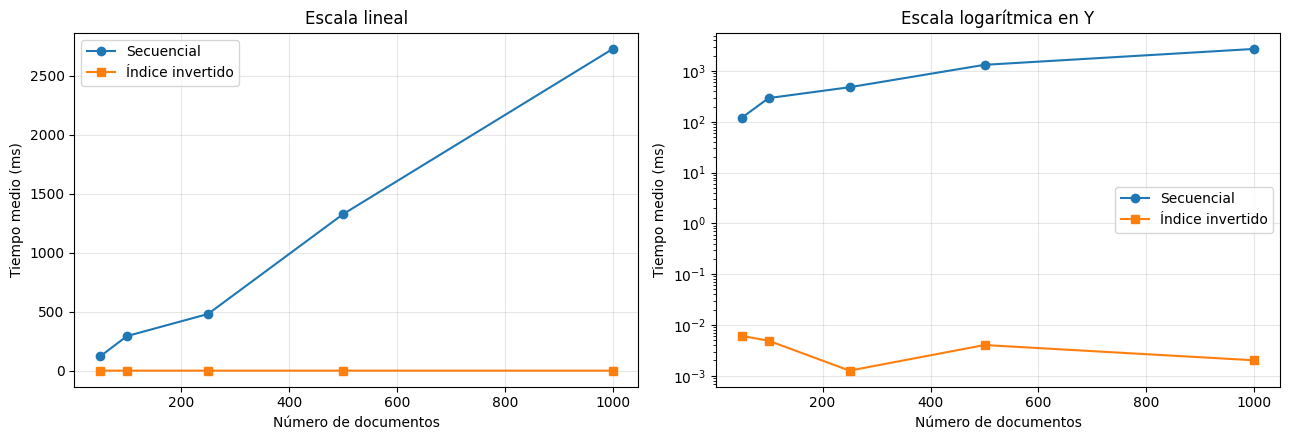

In [ ]:
TAMANOS = [50, 100, 250, 500, 1000]
CONSULTA_ESCALA = "corpse"   
                                

resultados = []
for n in TAMANOS:
    docs_n = cargar_docs(ids_muestra[:n])
    n_tokens = sum(len(t) for t in docs_n.values())

    # Secuencial
    t_sec = medir_tiempo(busqueda_secuencial, CONSULTA_ESCALA, docs_n)

    # Indice del subconjunto
    t0 = time.perf_counter()
    idx_n = construir_indice(docs_n)
    t_build = (time.perf_counter() - t0) * 1000

    # Consulta por índice
    t_idx = medir_tiempo(postings, idx_n, CONSULTA_ESCALA)

    # Verificación de igualdad
    assert busqueda_secuencial(CONSULTA_ESCALA, docs_n) == postings(idx_n, CONSULTA_ESCALA)

    resultados.append({"n_docs": n, "n_tokens": n_tokens,
                       "t_secuencial_ms": t_sec, "t_indice_ms": t_idx,
                       "t_construccion_indice_ms": t_build})
    print(resultados[-1])
    del docs_n, idx_n   # liberar memoria antes del siguiente tamaño

df_esc = pd.DataFrame(resultados)
display(df_esc)

# Gráfica
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, log in zip(ax, [False, True]):
    a.plot(df_esc.n_docs, df_esc.t_secuencial_ms, "o-", label="Secuencial")
    a.plot(df_esc.n_docs, df_esc.t_indice_ms, "s-", label="Índice invertido")
    a.set_xlabel("Número de documentos"); a.set_ylabel("Tiempo medio (ms)")
    if log: a.set_yscale("log"); a.set_title("Escala logarítmica en Y")
    else:   a.set_title("Escala lineal")
    a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

**El numero de tokens creció desde 3.5 millones de tokens a 60 millones de tokens aproximadamente, por lo que el tiempo que toma realizar la busqueda secuencial de un termino va aumentando linealmente, mientras que el tiempo que toma la busqueda por indice se mantiene muy equilibradoa medida que aumenta el numero de documentos. Un factor importante en el tiempo de ejecución es el uso riguroso de CPU y de memoria para hacer el volcado del vocabulario y la busqueda del temrino.**

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

Secuencial: t(n) = 2.764820·n + -60.6076   R² = 0.9933
Índice    : t(n) = -3.006e-06·n + 4.798e-03   R² = 0.3399


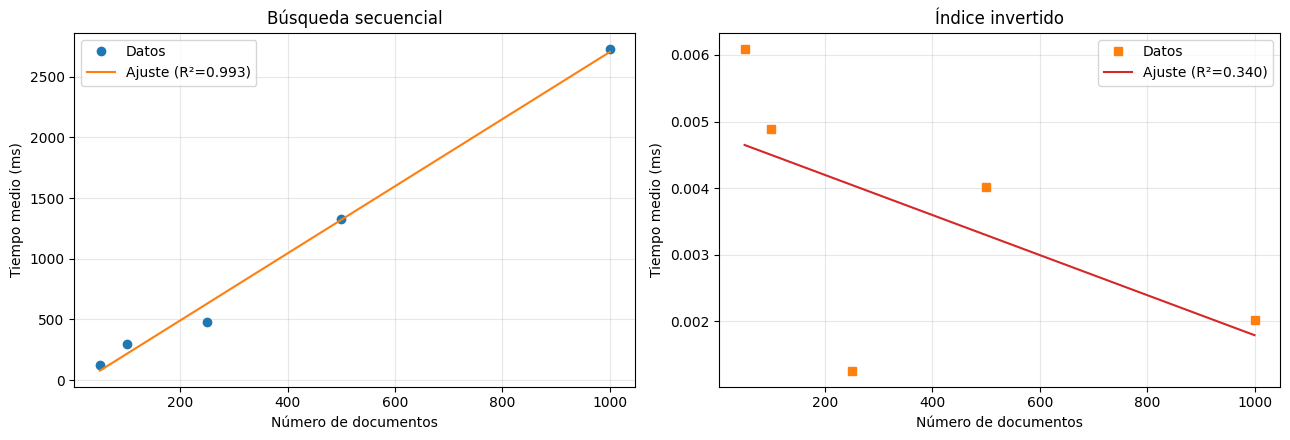

Secuencial vs tokens: R² = 0.9917


In [61]:
# Minimos cuadrados
def ajuste_lineal(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    a, b = np.polyfit(x, y, 1)                      
    pred = a * x + b
    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return a, b, r2

x = df_esc.n_docs.values
a_s, b_s, r2_s = ajuste_lineal(x, df_esc.t_secuencial_ms)
a_i, b_i, r2_i = ajuste_lineal(x, df_esc.t_indice_ms)

print(f"Secuencial: t(n) = {a_s:.6f}·n + {b_s:.4f}   R² = {r2_s:.4f}")
print(f"Índice    : t(n) = {a_i:.3e}·n + {b_i:.3e}   R² = {r2_i:.4f}")

xs = np.linspace(x.min(), x.max(), 200)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(x, df_esc.t_secuencial_ms, "o", label="Datos")
ax[0].plot(xs, a_s * xs + b_s, "-", label=f"Ajuste (R²={r2_s:.3f})")
ax[0].set_title("Búsqueda secuencial")

ax[1].plot(x, df_esc.t_indice_ms, "s", color="tab:orange", label="Datos")
ax[1].plot(xs, a_i * xs + b_i, "-", color="tab:red", label=f"Ajuste (R²={r2_i:.3f})")
ax[1].set_title("Índice invertido")

for a in ax:
    a.set_xlabel("Número de documentos"); a.set_ylabel("Tiempo medio (ms)")
    a.grid(alpha=.3); a.legend()
plt.tight_layout(); plt.show()

a_t, b_t, r2_t = ajuste_lineal(df_esc.n_tokens, df_esc.t_secuencial_ms)
print(f"Secuencial vs tokens: R² = {r2_t:.4f}")

## Interpretación
**Para la búsqueda secuencial, el modelo representa muy bien las mediciones y concuerda con su complejidad cuadrática: el tiempo crece proporcionalmente al número de tokens recorridos, que a su vez es proporcional al número de documentos, y la pendiente equivale a unos 2.76 ms por documento.En el índice invertido, en cambio, el ajuste da una pendiente prácticamente nula y un R² = 0.34, lo cual no indica un mal desempeño sino la ausencia de tendencia ya que sus tiempos fluctúan al azar alrededor de un valor constante, de modo que el modelo adeucado rondaría en los 4 µs.**